# 3. Scoring a week

How the backend will use the model: build features for every county for one week,
predict the probability, and explain what raises it. This is what step 2 builds on.

The live score will build `daily` from NASA POWER (observed days before the week) and
a forecast (the week itself). Here it's built from the cached NASA POWER history, for
the test week with the most fires, so we can check the predictions against what
happened.

In [1]:
import viz

viz.setup()

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml.wildfire import features as F
from ml.wildfire import sources
from ml.wildfire.config import (
    ARTIFACTS_DIR, CALIBRATION_YEARS, DATASET_PATH, FIRST_YEAR, LAST_YEAR,
    REFERENCE_PATH, REFIT_YEARS, TEST_YEARS, USER_AGENT,
)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

from matplotlib.colors import LinearSegmentedColormap, LogNorm

from ml.wildfire.model import WildfireModel

In [2]:
model = WildfireModel.load()
table = pd.read_parquet(DATASET_PATH)
test = table[table["year"].isin(list(TEST_YEARS))]
week = test.groupby("week_start")["fire"].sum().idxmax()
actual = table[table["week_start"] == week].set_index("fips")
print(f"Week of {week:%Y-%m-%d}: {int(actual['fire'].sum())} counties had a large fire start")

Week of 2024-07-22: 31 counties had a large fire start


`daily` holds one wide DataFrame per NASA POWER parameter. Rows are dates from 180 days
before the Monday to the Sunday, and columns are grid cells.

In [3]:
cells = model.county_cells.drop_duplicates("cell").set_index("cell")
start, end = week - pd.Timedelta(days=180), week + pd.Timedelta(days=6)
frames = {cell: sources.read_power_cell(row.cell_lat, row.cell_lon).loc[start:end] for cell, row in cells.iterrows()}
daily = {name: pd.DataFrame({cell: frame[name] for cell, frame in frames.items()}) for name in sources.POWER_PARAMETERS}
daily["T2M_MAX"].iloc[-7:, :5]

,32.500_-86.875,34.000_-86.875,33.000_-85.625,33.000_-86.875,34.500_-87.500
date,,,,,
2024-07-22,32.480000,30.540001,32.080002,30.990000,33.040001
2024-07-23,33.169998,29.549999,32.340000,31.620001,26.469999
2024-07-24,31.719999,29.639999,31.980000,32.480000,28.530001
2024-07-25,30.940001,31.020000,30.740000,28.410000,30.160000
2024-07-26,33.310001,31.590000,32.619999,32.889999,30.370001
2024-07-27,32.320000,32.459999,28.870001,31.629999,32.150002
2024-07-28,31.940001,28.549999,29.850000,31.740000,30.129999


In [4]:
X = model.features_for_week(daily, week)

# features_for_week uses today's fire history (fires through 2024), which would include
# this week's own fires. To score a past week fairly, use the history as it was then.
X[F.HISTORY_FEATURES] = actual.loc[X.index, F.HISTORY_FEATURES]

probability = pd.Series(model.predict(X), index=X.index, name="probability")
print(f"{len(X):,} counties scored. Mean weekly probability {probability.mean():.3%}, "
      f"expected fires {probability.sum():.1f}, actual {int(actual['fire'].sum())}")

3,221 counties scored. Mean weekly probability 0.856%, expected fires 27.6, actual 31


In [5]:
reference = json.loads(REFERENCE_PATH.read_text(encoding="utf-8"))["counties"]
names = pd.Series({fips: f"{c['name']}, {c['state']}" for fips, c in reference.items()})

ranked = probability.sort_values(ascending=False)
top_share = ranked.head(int(len(ranked) * 0.05)).index
fire_counties = actual.index[actual["fire"] == 1]
print(f"{fire_counties.isin(top_share).sum()} of {len(fire_counties)} fire counties were in the model's top 5% this week")

top = ranked.head(12).to_frame()
top.insert(0, "county", names.reindex(top.index))
top["fire this week"] = actual.loc[top.index, "fire"].map({1: "yes", 0: ""})
top.style.format({"probability": "{:.1%}"})

25 of 31 fire counties were in the model's top 5% this week


,county,probability,fire this week
fips,,,
41045,"Malheur County, OR",91.4%,yes
04005,"Coconino County, AZ",66.7%,
32013,"Humboldt County, NV",54.5%,
53047,"Okanogan County, WA",54.5%,
41025,"Harney County, OR",33.3%,yes
16073,"Owyhee County, ID",33.3%,yes
49045,"Tooele County, UT",33.3%,
32017,"Lincoln County, NV",33.3%,
32007,"Elko County, NV",33.3%,


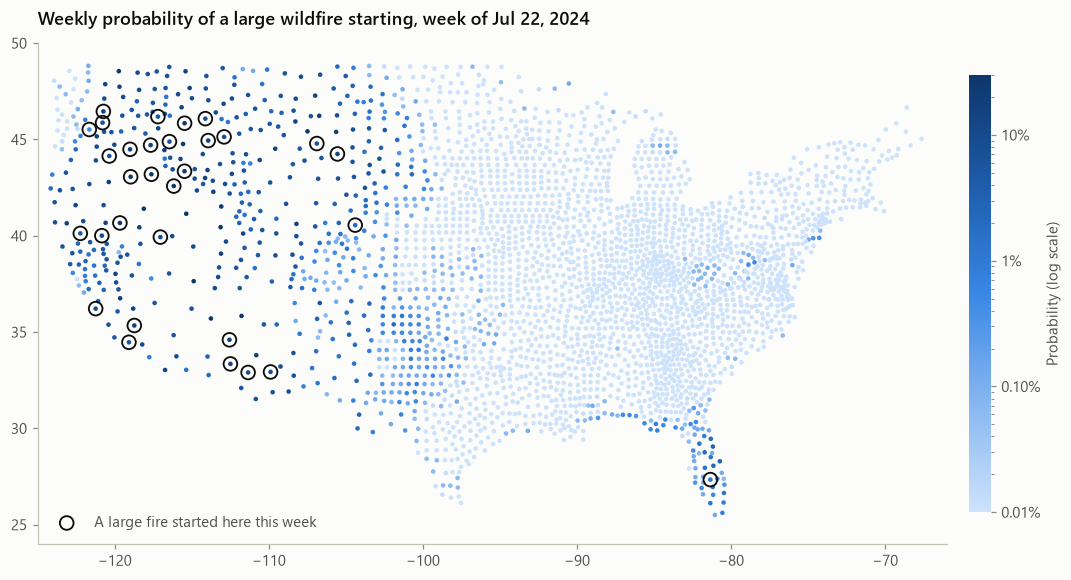

In [6]:
cmap = LinearSegmentedColormap.from_list("risk", viz.SEQUENTIAL)
counties = model.county_cells.join(pd.DataFrame(
    {"lat": [c["lat"] for c in reference.values()], "lon": [c["lon"] for c in reference.values()]},
    index=list(reference)))
counties["p"] = probability
lower48 = counties[counties["lon"].between(-125, -66) & counties["lat"].between(24, 50)]

fig, ax = plt.subplots(figsize=(10.5, 5.6))
points = ax.scatter(lower48["lon"], lower48["lat"], c=lower48["p"].clip(1e-4, 0.3), cmap=cmap,
                    norm=LogNorm(1e-4, 0.3), s=9, linewidths=0)
fired = lower48.loc[lower48.index.intersection(fire_counties)]
ax.scatter(fired["lon"], fired["lat"], s=80, facecolors="none", edgecolors=viz.INK, linewidths=1.2,
           label="A large fire started here this week")
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_aspect(1.25)
ax.grid(False)
ax.set_title(f"Weekly probability of a large wildfire starting, week of {week:%b %d, %Y}")
bar = fig.colorbar(points, ax=ax, shrink=0.75, pad=0.02)
bar.set_label("Probability (log scale)", color=viz.INK_SECONDARY)
bar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2%}" if v < 0.01 else f"{v:.0%}"))
bar.outline.set_visible(False)
ax.legend(loc="lower left")
viz.show()

## What raises a county's score

`model.explain` returns SHAP contributions in log-odds: positive values push the
probability up, negative values pull it down. These are the drivers the website can
show. Here is the highest-scoring county that had a fire this week.

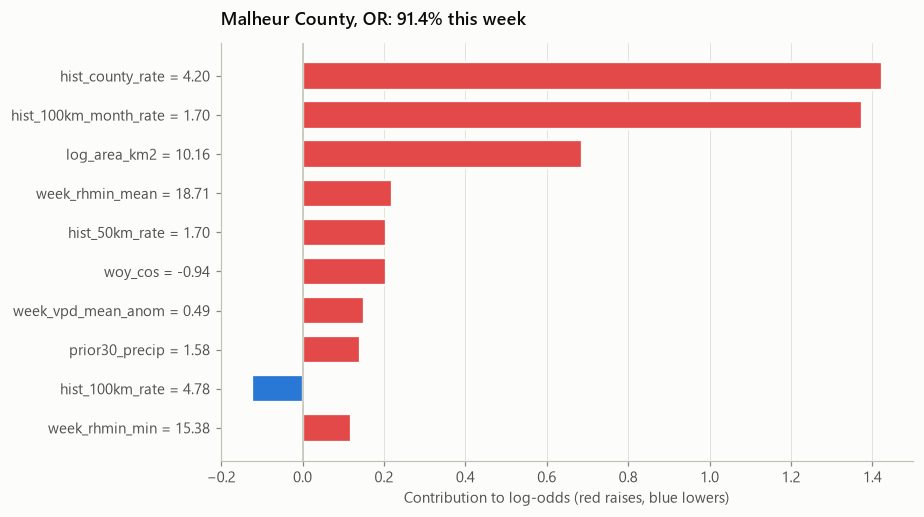

In [7]:
fips = ranked.index[ranked.index.isin(fire_counties)][0]
contributions = model.explain(X.loc[[fips]]).iloc[0]
drivers = contributions.drop("bias")
drivers = drivers.reindex(drivers.abs().sort_values(ascending=False).index).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
viz.hbars(ax, np.arange(len(drivers)), drivers.to_numpy(),
          color=[viz.RAISES if v > 0 else viz.LOWERS for v in drivers])
ax.set_yticks(np.arange(len(drivers)), [f"{name} = {X.loc[fips, name]:.2f}" for name in drivers.index])
ax.axvline(0, color=viz.AXIS, linewidth=1)
ax.set_title(f"{names[fips]}: {probability[fips]:.1%} this week")
ax.set_xlabel("Contribution to log-odds (red raises, blue lowers)")
viz.finish(ax, "x")
viz.show()

For the website, contributions can be summed into groups. The weather group is what
this week adds on top of the county's usual level.

In [8]:
groups = {"Weather this week": F.WEEK_FEATURES,
          "Dryness before the week": F.PRIOR_FEATURES,
          "Weather vs normal": F.ANOMALY_FEATURES,
          "Fire history": F.HISTORY_FEATURES,
          "Location": F.STATIC_FEATURES,
          "Season": F.SEASON_FEATURES}
explained = model.explain(X.loc[ranked.index[:8]])
grouped = pd.DataFrame({group: explained[members].sum(axis=1) for group, members in groups.items()})
grouped.insert(0, "county", names.reindex(grouped.index))
grouped.insert(1, "probability", probability.reindex(grouped.index))
grouped.style.format({"probability": "{:.1%}", **{g: "{:+.2f}" for g in groups}})

,county,probability,Weather this week,Dryness before the week,Weather vs normal,Fire history,Location,Season
fips,,,,,,,,
41045,"Malheur County, OR",91.4%,+0.39,+0.42,+0.07,+2.96,+0.66,+0.24
04005,"Coconino County, AZ",66.7%,+0.40,+0.04,+0.34,+2.98,+0.71,+0.22
32013,"Humboldt County, NV",54.5%,+0.43,+0.33,+0.17,+2.90,+0.55,+0.24
53047,"Okanogan County, WA",54.5%,+0.34,+0.21,-0.00,+3.09,+0.68,+0.25
41025,"Harney County, OR",33.3%,+0.41,+0.40,+0.14,+2.75,+0.60,+0.25
16073,"Owyhee County, ID",33.3%,+0.35,+0.38,+0.03,+3.04,+0.42,+0.23
49045,"Tooele County, UT",33.3%,+0.46,+0.35,+0.19,+2.91,+0.34,+0.23
32017,"Lincoln County, NV",33.3%,+0.41,+0.41,+0.55,+2.36,+0.45,+0.21
